In [ ]:

import os
from google.colab import files

print("Please upload your kaggle.json file:")
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise FileNotFoundError("kaggle.json was not uploaded. Please try again.")

# Configure Kaggle API permissions
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print("Kaggle API token configured successfully!")

# Create directory, download, and extract the DeepGlobe dataset
!mkdir -p /content/dataset
!kaggle datasets download -d balraj98/deepglobe-road-extraction-dataset -p /content/dataset
!unzip -q /content/dataset/deepglobe-road-extraction-dataset.zip -d /content/dataset/DeepGlobe
!rm /content/dataset/deepglobe-road-extraction-dataset.zip

print("Dataset downloaded and extracted to /content/dataset/DeepGlobe successfully!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Kaggle API token configured successfully!
Dataset URL: https://www.kaggle.com/datasets/balraj98/deepglobe-road-extraction-dataset
License(s): other
100% 3.79G/3.79G [00:36<00:00, 110MB/s]

Dataset downloaded and extracted to /content/dataset/DeepGlobe successfully!


In [ ]:

import os

def print_directory_structure(startpath, max_files=5):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * level
        print(f"{indent}{os.path.basename(root)}/")

        subindent = ' ' * 4 * (level + 1)

        # Sort files to see the naming conventions clearly (e.g., image vs mask)
        files.sort()

        for f in files[:max_files]:
            print(f"{subindent}{f}")

        if len(files) > max_files:
            print(f"{subindent}... and {len(files) - max_files} more files.")

dataset_path = "/content/dataset/DeepGlobe"
print(f"Directory structure of {dataset_path}:\n")
print_directory_structure(dataset_path)

Directory structure of /content/dataset/DeepGlobe:

DeepGlobe/
    class_dict.csv
    metadata.csv
    test/
        100393_sat.jpg
        100995_sat.jpg
        101982_sat.jpg
        10206_sat.jpg
        102240_sat.jpg
        ... and 1096 more files.
    train/
        100034_mask.png
        100034_sat.jpg
        100081_mask.png
        100081_sat.jpg
        100129_mask.png
        ... and 12447 more files.
    valid/
        100794_sat.jpg
        100905_sat.jpg
        102867_sat.jpg
        10417_sat.jpg
        106553_sat.jpg
        ... and 1238 more files.


In [ ]:

import os
import glob
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
from typing import Dict, List, Optional

def generate_connectivity_cube(mask: torch.Tensor, d: int) -> torch.Tensor:

    # Shape: [1, H, W]
    _, h, w = mask.shape

    # Pad the mask by 'd' pixels on all sides with 0.0
    # Pad format: (left, right, top, bottom)
    padded_mask = F.pad(mask, (d, d, d, d), mode='constant', value=0.0)  # Shape: [1, H+2d, W+2d]

    # Extract shifted versions corresponding to 8 neighbors using slicing
    # C1: Top-Left, C2: Top, C3: Top-Right
    # C4: Left,              C5: Right
    # C6: Bottom-Left, C7: Bottom, C8: Bottom-Right
    shifts = [
        padded_mask[:, 0:h, 0:w],           # C1: (-1, -1)
        padded_mask[:, 0:h, d:w+d],         # C2: (-1, 0)
        padded_mask[:, 0:h, 2*d:],          # C3: (-1, 1)
        padded_mask[:, d:h+d, 0:w],         # C4: (0, -1)
        padded_mask[:, d:h+d, 2*d:],        # C5: (0, 1)
        padded_mask[:, 2*d:, 0:w],          # C6: (1, -1)
        padded_mask[:, 2*d:, d:w+d],        # C7: (1, 0)
        padded_mask[:, 2*d:, 2*d:]          # C8: (1, 1)
    ]

    # Concatenate along the channel dimension
    cube = torch.cat(shifts, dim=0)  # Shape: [8, H, W]

    # Multiply with the center mask (Y_i,j * Y_neighbor)
    # Both must be 1 (road) to keep connectivity
    cube = cube * mask  # Shape: [8, H, W]

    return cube

In [ ]:

class CoANetDataset(Dataset):

    def __init__(self, root_dir: str, phase: str = 'train', img_size: int = 512, has_gt: bool = True):
        super().__init__()
        self.phase = phase
        self.img_size = img_size
        self.has_gt = has_gt

        # DeepGlobe stores training pairs inside the train folder
        phase_dir = os.path.join(root_dir, 'train' if phase in ['train', 'valid'] else phase)
        self.img_paths: List[str] = sorted(glob.glob(os.path.join(phase_dir, "*_sat.jpg")))

        if len(self.img_paths) == 0:
            raise ValueError(f"No images found in {phase_dir}")

        self.transform = self._get_transforms()

    def _get_transforms(self) -> A.Compose:
       
        if self.phase == 'train':
            return A.Compose([
                A.RandomScale(scale_limit=0.2, p=0.5),
                A.PadIfNeeded(min_height=self.img_size, min_width=self.img_size, border_mode=cv2.BORDER_CONSTANT),
                A.RandomCrop(width=self.img_size, height=self.img_size),
                A.HorizontalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                A.GaussianBlur(blur_limit=(3, 5), p=0.3),
                A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
                ToTensorV2()
            ])
        else:
            return A.Compose([
                A.Resize(height=self.img_size, width=self.img_size),
                A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
                ToTensorV2()
            ])

    def __len__(self) -> int:
        return len(self.img_paths)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        img_path = self.img_paths[idx]

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Load mask if ground-truth is available
        if self.has_gt:
            mask_path = img_path.replace('_sat.jpg', '_mask.png')
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask = (mask > 127).astype(np.float32)
        else:
            mask = np.zeros(image.shape[:2], dtype=np.float32)

        augmented = self.transform(image=image, mask=mask)
        img_tensor = augmented['image']
        mask_tensor = augmented['mask'].unsqueeze(0)

        conn_d1 = generate_connectivity_cube(mask_tensor, d=1)
        conn_d3 = generate_connectivity_cube(mask_tensor, d=3)

        return {
            'image': img_tensor,
            'seg_target': mask_tensor,
            'conn_d1_target': conn_d1,
            'conn_d3_target': conn_d3
        }

In [ ]:

def test_dataloader():
    dataset_path = "/content/dataset/DeepGlobe"

    # Initialize dataset and dataloader
    train_dataset = CoANetDataset(root_dir=dataset_path, phase='train', img_size=512)
    train_loader = DataLoader(
        train_dataset,
        batch_size=8,        # Adjusted for Colab memory limits
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    print(f"Total training images: {len(train_dataset)}")
    print("Fetching one batch to verify shape contracts...\n")

    # Get a single batch
    batch = next(iter(train_loader))

    # Verify Shapes and Data Types
    for key, tensor in batch.items():
        print(f"Key: '{key}'")
        print(f"  Shape: {tensor.shape}")
        print(f"  Dtype: {tensor.dtype}")
        print(f"  Min Value: {tensor.min().item():.4f}, Max Value: {tensor.max().item():.4f}")
        print("-" * 40)

# Run the test
test_dataloader()

Total training images: 6226
Fetching one batch to verify shape contracts...



/tmp/ipykernel_795/3851626117.py:26: UserWarning: Argument(s) 'value' are not valid for transform PadIfNeeded
  A.PadIfNeeded(min_height=self.img_size, min_width=self.img_size, border_mode=cv2.BORDER_CONSTANT, value=0),


Key: 'image'
  Shape: torch.Size([8, 3, 512, 512])
  Dtype: torch.float32
  Min Value: -2.0357, Max Value: 2.6400
----------------------------------------
Key: 'seg_target'
  Shape: torch.Size([8, 1, 512, 512])
  Dtype: torch.float32
  Min Value: 0.0000, Max Value: 1.0000
----------------------------------------
Key: 'conn_d1_target'
  Shape: torch.Size([8, 8, 512, 512])
  Dtype: torch.float32
  Min Value: 0.0000, Max Value: 1.0000
----------------------------------------
Key: 'conn_d3_target'
  Shape: torch.Size([8, 8, 512, 512])
  Dtype: torch.float32
  Min Value: 0.0000, Max Value: 1.0000
----------------------------------------


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet101, ResNet101_Weights
from typing import Tuple, Dict

class ResNet101Encoder(nn.Module):

    def __init__(self, pretrained: bool = True):
        super().__init__()
        weights = ResNet101_Weights.DEFAULT if pretrained else None
        
        backbone = resnet101(weights=weights, replace_stride_with_dilation=[False, True, True])

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool
        )
        self.layer1 = backbone.layer1  # Output channels: 256, Stride: 4
        self.layer2 = backbone.layer2  # Output channels: 512, Stride: 8
        self.layer3 = backbone.layer3  # Output channels: 1024, Stride: 8 (dilation r=2)
        self.layer4 = backbone.layer4  # Output channels: 2048, Stride: 8 (dilation r=4)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        # Input x Shape: [B, 3, 512, 512]
        s1 = self.stem(x)      # Shape: [B, 64, 128, 128]   --> Skip_1
        s2 = self.layer1(s1)   # Shape: [B, 256, 128, 128]  --> Skip_2
        s3 = self.layer2(s2)   # Shape: [B, 512, 64, 64]    --> Skip_3
        s4 = self.layer3(s3)   # Shape: [B, 1024, 64, 64]   --> Skip_4
        out = self.layer4(s4)  # Shape: [B, 2048, 64, 64]   --> Deep Features
        return s1, s2, s3, s4, out


class ASPPModule(nn.Module):

    def __init__(self, in_channels: int = 2048, out_channels: int = 256):
        super().__init__()

        # Branch 1: 1x1 Convolution
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Branch 2: 3x3 Atrous Convolution (r=6)
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=6, dilation=6, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Branch 3: 3x3 Atrous Convolution (r=12)
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=12, dilation=12, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Branch 4: 3x3 Atrous Convolution (r=18)
        self.branch4 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=18, dilation=18, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Branch 5: Global Average Pooling
        self.branch5_pool = nn.AdaptiveAvgPool2d(1)
        self.branch5_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        # Projection Layer (5 * 256 = 1280 -> 256)
        self.project = nn.Sequential(
            nn.Conv2d(out_channels * 5, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input x Shape: [B, 2048, 64, 64]
        h, w = x.shape[2], x.shape[3]

        b1 = self.branch1(x)  # Shape: [B, 256, 64, 64]
        b2 = self.branch2(x)  # Shape: [B, 256, 64, 64]
        b3 = self.branch3(x)  # Shape: [B, 256, 64, 64]
        b4 = self.branch4(x)  # Shape: [B, 256, 64, 64]

        b5 = self.branch5_pool(x)  # Shape: [B, 2048, 1, 1]
        b5 = self.branch5_conv(b5) # Shape: [B, 256, 1, 1]
        b5 = F.interpolate(b5, size=(h, w), mode='bilinear', align_corners=False)  # Shape: [B, 256, 64, 64]

        concat = torch.cat([b1, b2, b3, b4, b5], dim=1)  # Shape: [B, 1280, 64, 64]
        out = self.project(concat)                       # Shape: [B, 256, 64, 64]
        return out

In [ ]:

class DiagonalStripConv2d(nn.Module):

    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 9, direction: str = 'left'):
        super().__init__()
        padding = kernel_size // 2
        self.stride = 1
        self.padding = padding
        self.weight = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))

        # Create binary diagonal mask (1 on diagonal, 0 elsewhere)
        mask = torch.zeros(kernel_size, kernel_size)
        if direction == 'left':  # Main diagonal: D = (1, 1)
            for i in range(kernel_size):
                mask[i, i] = 1.0
        elif direction == 'right':  # Anti-diagonal: D = (-1, 1)
            for i in range(kernel_size):
                mask[i, kernel_size - 1 - i] = 1.0
        else:
            raise ValueError("direction must be 'left' or 'right'")

        self.register_buffer('mask', mask.view(1, 1, kernel_size, kernel_size))
        nn.init.kaiming_normal_(self.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        masked_weight = self.weight * self.mask
        return F.conv2d(x, masked_weight, bias=None, stride=self.stride, padding=self.padding)


class StripConvolutionBlock(nn.Module):

    def __init__(self, in_channels: int, out_channels: int = 256, kernel_len: int = 9):
        super().__init__()
        mid_channels = out_channels // 4  # 64 channels per directional branch
        pad = kernel_len // 2             # pad = 4 for kernel_len = 9

        # Initial 1x1 channel reduction
        self.conv_in = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True)
        )

        # 4 Parallel Directional Strip Convolutions
        self.strip_h = nn.Conv2d(mid_channels, mid_channels, kernel_size=(1, kernel_len), padding=(0, pad), bias=False)
        self.strip_v = nn.Conv2d(mid_channels, mid_channels, kernel_size=(kernel_len, 1), padding=(pad, 0), bias=False)
        self.strip_d_left = DiagonalStripConv2d(mid_channels, mid_channels, kernel_size=kernel_len, direction='left')
        self.strip_d_right = DiagonalStripConv2d(mid_channels, mid_channels, kernel_size=kernel_len, direction='right')

        self.bn_strips = nn.BatchNorm2d(mid_channels * 4)
        self.relu_strips = nn.ReLU(inplace=True)

        # Output 1x1 projection
        self.conv_out = nn.Sequential(
            nn.Conv2d(mid_channels * 4, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input x Shape: [B, C_in, H, W]
        feat = self.conv_in(x)  # Shape: [B, 64, H, W]

        h_feat = self.strip_h(feat)        # Shape: [B, 64, H, W]
        v_feat = self.strip_v(feat)        # Shape: [B, 64, H, W]
        dl_feat = self.strip_d_left(feat)  # Shape: [B, 64, H, W]
        dr_feat = self.strip_d_right(feat) # Shape: [B, 64, H, W]

        concat = torch.cat([h_feat, v_feat, dl_feat, dr_feat], dim=1)  # Shape: [B, 256, H, W]
        concat = self.relu_strips(self.bn_strips(concat))              # Shape: [B, 256, H, W]

        out = self.conv_out(concat)  # Shape: [B, 256, H, W]
        return out


class CoANetDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        # 1x1 Convolutions for Skip Connections to reduce channels to 256
        self.skip4_conv = nn.Sequential(
            nn.Conv2d(1024, 256, kernel_size=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )
        self.skip2_conv = nn.Sequential(
            nn.Conv2d(256, 256, kernel_size=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        # 4 Strip Convolution Blocks
        self.scb1 = StripConvolutionBlock(in_channels=512, out_channels=256)
        self.scb2 = StripConvolutionBlock(in_channels=512, out_channels=256)
        self.scb3 = StripConvolutionBlock(in_channels=256, out_channels=256)
        self.scb4 = StripConvolutionBlock(in_channels=256, out_channels=256)

    def forward(self, aspp_out: torch.Tensor, skip4: torch.Tensor, skip2: torch.Tensor) -> torch.Tensor:
        # aspp_out: [B, 256, 64, 64], skip4: [B, 1024, 64, 64], skip2: [B, 256, 128, 128]

        # Decoder Block 1 (64x64)
        s4 = self.skip4_conv(skip4)             # Shape: [B, 256, 64, 64]
        d1 = torch.cat([aspp_out, s4], dim=1)   # Shape: [B, 512, 64, 64]
        d1 = self.scb1(d1)                      # Shape: [B, 256, 64, 64]

        # Decoder Block 2 (64x64 -> 128x128)
        d2 = F.interpolate(d1, scale_factor=2.0, mode='bilinear', align_corners=False)  # Shape: [B, 256, 128, 128]
        s2 = self.skip2_conv(skip2)             # Shape: [B, 256, 128, 128]
        d2 = torch.cat([d2, s2], dim=1)         # Shape: [B, 512, 128, 128]
        d2 = self.scb2(d2)                      # Shape: [B, 256, 128, 128]

        # Decoder Block 3 (128x128 -> 256x256)
        d3 = F.interpolate(d2, scale_factor=2.0, mode='bilinear', align_corners=False)  # Shape: [B, 256, 256, 256]
        d3 = self.scb3(d3)                      # Shape: [B, 256, 256, 256]

        # Decoder Block 4 (256x256 -> 512x512)
        d4 = F.interpolate(d3, scale_factor=2.0, mode='bilinear', align_corners=False)  # Shape: [B, 256, 512, 512]
        d4 = self.scb4(d4)                      # Shape: [B, 256, 512, 512]

        return d4

In [ ]:

class ConnectivityAttentionModule(nn.Module):

    def __init__(self, in_channels: int = 256, mid_channels: int = 128, dilation: int = 1, reduction: int = 16):
        super().__init__()

        # Base 3x3 Conv-BN-ReLU
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True)
        )

        # 3x3 Atrous Conv-BN-ReLU with dilation rate r = d
        self.atrous_conv = nn.Sequential(
            nn.Conv2d(mid_channels, mid_channels, kernel_size=3, padding=dilation, dilation=dilation, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True)
        )

        # Squeeze-and-Excitation (SE) Block
        self.se_pool = nn.AdaptiveAvgPool2d(1)
        self.se_fc = nn.Sequential(
            nn.Linear(mid_channels, mid_channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid_channels // reduction, mid_channels, bias=False),
            nn.Sigmoid()
        )

        # Final 1x1 Conv head mapping to 8 connectivity channels
        self.head = nn.Conv2d(mid_channels, 8, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input x Shape: [B, 256, 512, 512]
        feat = self.conv1(x)           # Shape: [B, 128, 512, 512]
        feat = self.atrous_conv(feat)  # Shape: [B, 128, 512, 512]

        # SE Block Attention
        b, c, _, _ = feat.shape
        se_weights = self.se_pool(feat).view(b, c)          # Shape: [B, 128]
        se_weights = self.se_fc(se_weights).view(b, c, 1, 1) # Shape: [B, 128, 1, 1]

        calibrated_feat = feat * se_weights  # Shape: [B, 128, 512, 512]
        out = self.head(calibrated_feat)     # Shape: [B, 8, 512, 512]
        return out


class SegmentationHead(nn.Module):

    def __init__(self, in_channels: int = 256, mid_channels: int = 64):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, 1, kernel_size=1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input x Shape: [B, 256, 512, 512]
        out = self.block(x)  # Shape: [B, 1, 512, 512]
        return out


class CoANet(nn.Module):

    def __init__(self, pretrained_backbone: bool = True):
        super().__init__()
        self.encoder = ResNet101Encoder(pretrained=pretrained_backbone)
        self.aspp = ASPPModule(in_channels=2048, out_channels=256)
        self.decoder = CoANetDecoder()

        self.seg_head = SegmentationHead(in_channels=256, mid_channels=64)
        self.coa_d1 = ConnectivityAttentionModule(in_channels=256, mid_channels=128, dilation=1)
        self.coa_d3 = ConnectivityAttentionModule(in_channels=256, mid_channels=128, dilation=3)

        # Initialize custom modules (excluding pretrained encoder)
        self._init_custom_weights()

    def _init_custom_weights(self) -> None:
        
        custom_modules = [self.aspp, self.decoder, self.seg_head, self.coa_d1, self.coa_d3]
        for module in custom_modules:
            for m in module.modules():
                if isinstance(m, nn.Conv2d):
                    nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                    if m.bias is not None:
                        nn.init.constant_(m.bias, 0.0)
                elif isinstance(m, nn.BatchNorm2d):
                    nn.init.constant_(m.weight, 1.0)
                    nn.init.constant_(m.bias, 0.0)
                elif isinstance(m, nn.Linear):
                    nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                    if m.bias is not None:
                        nn.init.constant_(m.bias, 0.0)

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        # Input x Shape: [B, 3, 512, 512]
        _, s2, _, s4, enc_out = self.encoder(x)
        # s2: [B, 256, 128, 128], s4: [B, 1024, 64, 64], enc_out: [B, 2048, 64, 64]

        aspp_out = self.aspp(enc_out)                        # Shape: [B, 256, 64, 64]
        dec_out = self.decoder(aspp_out, skip4=s4, skip2=s2) # Shape: [B, 256, 512, 512]

        seg_logits = self.seg_head(dec_out)     # Shape: [B, 1, 512, 512]
        conn_d1_logits = self.coa_d1(dec_out)   # Shape: [B, 8, 512, 512]
        conn_d3_logits = self.coa_d3(dec_out)   # Shape: [B, 8, 512, 512]

        return {
            'seg_logits': seg_logits,
            'conn_d1_logits': conn_d1_logits,
            'conn_d3_logits': conn_d3_logits
        }

    @torch.no_grad()
    def inference_fusion(self, x: torch.Tensor, threshold: float = 0.5) -> torch.Tensor:

        outputs = self.forward(x)
        seg_prob = torch.sigmoid(outputs['seg_logits'])         # Shape: [B, 1, H, W]
        conn_d1_prob = torch.sigmoid(outputs['conn_d1_logits']) # Shape: [B, 8, H, W]
        conn_d3_prob = torch.sigmoid(outputs['conn_d3_logits']) # Shape: [B, 8, H, W]

        # Threshold connectivity cubes and sum over 8 channels to form enhancing masks
        conn_d1_mask = (conn_d1_prob > threshold).float().sum(dim=1, keepdim=True) / 8.0  # Shape: [B, 1, H, W]
        conn_d3_mask = (conn_d3_prob > threshold).float().sum(dim=1, keepdim=True) / 8.0  # Shape: [B, 1, H, W]

        fused_prob = torch.clamp(seg_prob + 0.5 * (conn_d1_mask + conn_d3_mask), min=0.0, max=1.0)
        return fused_prob

In [ ]:

def verify_coanet_architecture():
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Running verification on device: {device}")

    # Initialize model
    model = CoANet(pretrained_backbone=True).to(device)
    model.eval()

    # Count trainable parameters
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total Trainable Parameters: {total_params:,}\n")

    # Create dummy input tensor [B=2, C=3, H=512, W=512]
    dummy_input = torch.randn(2, 3, 512, 512, device=device)
    print(f"Dummy Input Shape: {dummy_input.shape}")
    print("-" * 50)

    with torch.no_grad():
        outputs = model(dummy_input)
        fused_output = model.inference_fusion(dummy_input, threshold=0.5)

    for key, tensor in outputs.items():
        print(f"Output '{key}':")
        print(f"  Shape: {tensor.shape} | Dtype: {tensor.dtype}")

    print("-" * 50)
    print(f"Inference Fused Output Shape: {fused_output.shape}")
    print("Architecture verification completed successfully!")


verify_coanet_architecture()

Running verification on device: cuda
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:01<00:00, 98.7MB/s]


Total Trainable Parameters: 62,717,713

Dummy Input Shape: torch.Size([2, 3, 512, 512])
--------------------------------------------------
Output 'seg_logits':
  Shape: torch.Size([2, 1, 512, 512]) | Dtype: torch.float32
Output 'conn_d1_logits':
  Shape: torch.Size([2, 8, 512, 512]) | Dtype: torch.float32
Output 'conn_d3_logits':
  Shape: torch.Size([2, 8, 512, 512]) | Dtype: torch.float32
--------------------------------------------------
Inference Fused Output Shape: torch.Size([2, 1, 512, 512])
Architecture verification completed successfully!


In [ ]:

import torch
import torch.nn as nn
from typing import Dict

class SoftDiceLoss(nn.Module):

    def __init__(self, smooth: float = 1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # logits Shape: [B, 1, H, W], targets Shape: [B, 1, H, W]
        probs = torch.sigmoid(logits)  # Shape: [B, 1, H, W]

        # Flatten spatial dimensions per sample in batch
        probs_flat = probs.view(probs.size(0), -1)      # Shape: [B, H*W]
        targets_flat = targets.view(targets.size(0), -1) # Shape: [B, H*W]

        intersection = (probs_flat * targets_flat).sum(dim=1)                  # Shape: [B]
        denominator = (probs_flat ** 2).sum(dim=1) + (targets_flat ** 2).sum(dim=1) # Shape: [B]

        dice_score = (2.0 * intersection + self.smooth) / (denominator + self.smooth)
        dice_loss = 1.0 - dice_score.mean()
        return dice_loss


class CoANetMultiTaskLoss(nn.Module):

    def __init__(self, alpha: float = 1.0, beta: float = 1.0, lambda_weight: float = 1.0):
        super().__init__()
        self.alpha = alpha
        self.beta = beta
        self.lambda_weight = lambda_weight

        self.bce_loss = nn.BCEWithLogitsLoss(reduction='mean')
        self.dice_loss = SoftDiceLoss()

    def forward(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: Dict[str, torch.Tensor]
    ) -> Dict[str, torch.Tensor]:
        # Unpack predictions
        pred_seg = outputs['seg_logits']         # Shape: [B, 1, 512, 512]
        pred_conn_d1 = outputs['conn_d1_logits'] # Shape: [B, 8, 512, 512]
        pred_conn_d3 = outputs['conn_d3_logits'] # Shape: [B, 8, 512, 512]

        # Unpack ground-truth targets
        target_seg = targets['seg_target']         # Shape: [B, 1, 512, 512]
        target_conn_d1 = targets['conn_d1_target'] # Shape: [B, 8, 512, 512]
        target_conn_d3 = targets['conn_d3_target'] # Shape: [B, 8, 512, 512]

        # 1. Segmentation Loss
        l_bce = self.bce_loss(pred_seg, target_seg)
        l_dice = self.dice_loss(pred_seg, target_seg)
        l_seg = l_bce + self.alpha * l_dice

        # 2. Connectivity Loss (averaged across 8 channels and spatial locations)
        l_d1 = self.bce_loss(pred_conn_d1, target_conn_d1)
        l_d3 = self.bce_loss(pred_conn_d3, target_conn_d3)
        l_con = l_d1 + self.beta * l_d3

        # 3. Total Loss
        total_loss = l_seg + self.lambda_weight * l_con

        return {
            'total_loss': total_loss,
            'seg_loss': l_seg.detach(),
            'conn_loss': l_con.detach(),
            'dice_loss': l_dice.detach()
        }

In [ ]:

import torch.optim as optim
from torch.optim.lr_scheduler import PolynomialLR
from typing import Tuple

@torch.no_grad()
def compute_fused_binary_prediction(
    outputs: Dict[str, torch.Tensor],
    conn_threshold: float = 0.5,
    final_threshold: float = 0.5
) -> torch.Tensor:

    seg_prob = torch.sigmoid(outputs['seg_logits'])         # Shape: [B, 1, H, W]
    conn_d1_prob = torch.sigmoid(outputs['conn_d1_logits']) # Shape: [B, 8, H, W]
    conn_d3_prob = torch.sigmoid(outputs['conn_d3_logits']) # Shape: [B, 8, H, W]

    # Threshold connectivity predictions at t and sum over the 8 channels
    conn_d1_sum = (conn_d1_prob > conn_threshold).float().sum(dim=1, keepdim=True) / 8.0  # Shape: [B, 1, H, W]
    conn_d3_sum = (conn_d3_prob > conn_threshold).float().sum(dim=1, keepdim=True) / 8.0  # Shape: [B, 1, H, W]

    fused_score = seg_prob + 0.5 * (conn_d1_sum + conn_d3_sum)  # Shape: [B, 1, H, W]
    binary_pred = (fused_score > final_threshold).float()       # Shape: [B, 1, H, W]
    return binary_pred


class RoadMetricsTracker:

    def __init__(self, eps: float = 1e-6):
        self.eps = eps
        self.reset()

    def reset(self) -> None:
        self.tp = 0.0
        self.fp = 0.0
        self.fn = 0.0

    @torch.no_grad()
    def update(self, pred_binary: torch.Tensor, target_binary: torch.Tensor) -> None:
        # pred_binary: [B, 1, H, W], target_binary: [B, 1, H, W]
        pred_flat = pred_binary.view(-1)
        target_flat = target_binary.view(-1)

        self.tp += (pred_flat * target_flat).sum().item()
        self.fp += (pred_flat * (1.0 - target_flat)).sum().item()
        self.fn += ((1.0 - pred_flat) * target_flat).sum().item()

    def compute(self) -> Dict[str, float]:
        precision = (self.tp + self.eps) / (self.tp + self.fp + self.eps)
        recall = (self.tp + self.eps) / (self.tp + self.fn + self.eps)
        f1 = (2.0 * precision * recall) / (precision + recall + self.eps)
        iou = (self.tp + self.eps) / (self.tp + self.fp + self.fn + self.eps)

        return {
            'IoU': iou,
            'F1': f1,
            'Precision': precision,
            'Recall': recall
        }


def build_optimizer_and_scheduler(
    model: nn.Module,
    max_iterations: int,
    base_lr: float = 0.01,
    momentum: float = 0.9,
    weight_decay: float = 5e-4,
    power: float = 3.0
) -> Tuple[optim.Optimizer, PolynomialLR]:

    optimizer = optim.SGD(
        model.parameters(),
        lr=base_lr,
        momentum=momentum,
        weight_decay=weight_decay
    )
    scheduler = PolynomialLR(
        optimizer,
        total_iters=max_iterations,
        power=power
    )
    return optimizer, scheduler

In [ ]:

import time
from tqdm.auto import tqdm

def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    scheduler: PolynomialLR,
    scaler: torch.amp.GradScaler,
    device: str,
    epoch: int,
    num_epochs: int,
    accumulation_steps: int = 2,
    max_grad_norm: float = 10.0
) -> Dict[str, float]:

    model.train()
    start_time = time.time()

    running_total_loss = 0.0
    running_seg_loss = 0.0
    running_conn_loss = 0.0
    num_batches = len(dataloader)

    optimizer.zero_grad(set_to_none=True)
    pbar = tqdm(enumerate(dataloader), total=num_batches, desc=f"Epoch [{epoch+1}/{num_epochs}] Train", leave=False)

    for batch_idx, batch in pbar:
        images = batch['image'].to(device, non_blocking=True)                  # Shape: [B, 3, 512, 512]
        targets = {
            'seg_target': batch['seg_target'].to(device, non_blocking=True),         # Shape: [B, 1, 512, 512]
            'conn_d1_target': batch['conn_d1_target'].to(device, non_blocking=True), # Shape: [B, 8, 512, 512]
            'conn_d3_target': batch['conn_d3_target'].to(device, non_blocking=True)  # Shape: [B, 8, 512, 512]
        }

        with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
            outputs = model(images)
            loss_dict = criterion(outputs, targets)
            # Normalize loss by accumulation_steps
            scaled_loss = loss_dict['total_loss'] / accumulation_steps

        scaler.scale(scaled_loss).backward()

        # Step optimizer every accumulation_steps or on the last batch
        if ((batch_idx + 1) % accumulation_steps == 0) or ((batch_idx + 1) == num_batches):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        running_total_loss += loss_dict['total_loss'].item()
        running_seg_loss += loss_dict['seg_loss'].item()
        running_conn_loss += loss_dict['conn_loss'].item()

        current_lr = optimizer.param_groups[0]['lr']
        pbar.set_postfix({
            'Loss': f"{loss_dict['total_loss'].item():.4f}",
            'Seg': f"{loss_dict['seg_loss'].item():.4f}",
            'Conn': f"{loss_dict['conn_loss'].item():.4f}",
            'LR': f"{current_lr:.6f}"
        })

    epoch_duration = time.time() - start_time
    return {
        'total_loss': running_total_loss / num_batches,
        'seg_loss': running_seg_loss / num_batches,
        'conn_loss': running_conn_loss / num_batches,
        'duration_sec': epoch_duration
    }


@torch.no_grad()
def validate_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    device: str,
    epoch: int,
    num_epochs: int
) -> Dict[str, float]:

    model.eval()
    start_time = time.time()

    running_total_loss = 0.0
    metrics_tracker = RoadMetricsTracker()
    num_batches = len(dataloader)

    pbar = tqdm(dataloader, total=num_batches, desc=f"Epoch [{epoch+1}/{num_epochs}] Valid", leave=False)

    for batch in pbar:
        images = batch['image'].to(device, non_blocking=True)
        targets = {
            'seg_target': batch['seg_target'].to(device, non_blocking=True),
            'conn_d1_target': batch['conn_d1_target'].to(device, non_blocking=True),
            'conn_d3_target': batch['conn_d3_target'].to(device, non_blocking=True)
        }

        with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
            outputs = model(images)
            loss_dict = criterion(outputs, targets)

        running_total_loss += loss_dict['total_loss'].item()

        # Compute fused road prediction and update metrics
        fused_preds = compute_fused_binary_prediction(outputs, conn_threshold=0.5, final_threshold=0.5)
        metrics_tracker.update(fused_preds, targets['seg_target'])

    val_metrics = metrics_tracker.compute()
    val_metrics['val_loss'] = running_total_loss / num_batches
    val_metrics['duration_sec'] = time.time() - start_time
    return val_metrics

In [ ]:

def run_pipeline_sanity_check():
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dataset_path = "/content/dataset/DeepGlobe"

    print("Initializing End-to-End Sanity Check (Data -> Model -> Loss -> Backward -> Step)...")
    dataset = CoANetDataset(root_dir=dataset_path, phase='train', img_size=512)
    loader = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)

    model = CoANet(pretrained_backbone=True).to(device)
    criterion = CoANetMultiTaskLoss(alpha=1.0, beta=1.0, lambda_weight=1.0)
    optimizer, scheduler = build_optimizer_and_scheduler(model, max_iterations=100, base_lr=0.01)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    # Fetch one batch
    batch = next(iter(loader))
    images = batch['image'].to(device)
    targets = {
        'seg_target': batch['seg_target'].to(device),
        'conn_d1_target': batch['conn_d1_target'].to(device),
        'conn_d3_target': batch['conn_d3_target'].to(device)
    }

    # Warm-up CUDA and time a full forward + backward step
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()

    model.train()
    optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
        outputs = model(images)
        loss_dict = criterion(outputs, targets)

    scaler.scale(loss_dict['total_loss']).backward()
    scaler.unscale_(optimizer)
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()

    if device == "cuda":
        torch.cuda.synchronize()
    step_time = time.time() - t0

    print("-" * 60)
    print(f"Sanity Check Status : PASSED")
    print(f"Total Loss          : {loss_dict['total_loss'].item():.4f}")
    print(f"  ├── Seg Loss      : {loss_dict['seg_loss'].item():.4f} (Dice Loss: {loss_dict['dice_loss'].item():.4f})")
    print(f"  └── Conn Loss     : {loss_dict['conn_loss'].item():.4f}")
    print(f"Gradient Norm       : {grad_norm.item():.4f}")
    print(f"Single Batch Time   : {step_time:.3f} seconds (Batch Size = 4)")
    print("-" * 60)


run_pipeline_sanity_check()

Initializing End-to-End Sanity Check (Data -> Model -> Loss -> Backward -> Step)...


/tmp/ipykernel_795/3851626117.py:26: UserWarning: Argument(s) 'value' are not valid for transform PadIfNeeded
  A.PadIfNeeded(min_height=self.img_size, min_width=self.img_size, border_mode=cv2.BORDER_CONSTANT, value=0),


------------------------------------------------------------
Sanity Check Status : PASSED
Total Loss          : 4.7594
  ├── Seg Loss      : 2.8558 (Dice Loss: 0.8964)
  └── Conn Loss     : 1.9036
Gradient Norm       : 12.3178
Single Batch Time   : 2.768 seconds (Batch Size = 4)
------------------------------------------------------------


In [ ]:

import copy
import time
import gc
import os
import torch
from torch.utils.data import DataLoader


NUM_EPOCHS = 10
BATCH_SIZE = 4               # Increased to 4 for faster GPU execution
ACCUMULATION_STEPS = 4       # Effective Batch Size = 16 (4 x 4)
BASE_LR = 0.01
VAL_SPLIT_RATIO = 0.10
CHECKPOINT_DIR = "/content/drive/MyDrive/CoANet_Checkpoints"
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_coanet.pth")
LAST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "last_checkpoint.pth")
RESUME_TRAINING = True


def run_training():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    device = "cuda" if torch.cuda.is_available() else "cpu"
    dataset_path = "/content/dataset/DeepGlobe"

    # 1. Dataset splits (both with has_gt=True)
    full_train_dataset = CoANetDataset(root_dir=dataset_path, phase='train', img_size=512, has_gt=True)
    val_dataset = copy.deepcopy(full_train_dataset)
    val_dataset.phase = 'valid'
    val_dataset.has_gt = True
    val_dataset.transform = val_dataset._get_transforms()

    total_samples = len(full_train_dataset)
    val_size = int(total_samples * VAL_SPLIT_RATIO)
    train_size = total_samples - val_size

    generator = torch.Generator().manual_seed(42)
    train_indices, val_indices = torch.utils.data.random_split(
        range(total_samples), [train_size, val_size], generator=generator
    )

    train_data = torch.utils.data.Subset(full_train_dataset, train_indices.indices)
    val_data = torch.utils.data.Subset(val_dataset, val_indices.indices)

    train_loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        drop_last=True,
        persistent_workers=True
    )
    val_loader = DataLoader(
        val_data,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
        persistent_workers=True
    )

    # 2. Model & Optimizers
    model = CoANet(pretrained_backbone=True).to(device)
    criterion = CoANetMultiTaskLoss(alpha=1.0, beta=1.0, lambda_weight=1.0)

    steps_per_epoch = len(train_loader) // ACCUMULATION_STEPS
    max_iterations = max(1, NUM_EPOCHS * steps_per_epoch)

    optimizer, scheduler = build_optimizer_and_scheduler(
        model=model,
        max_iterations=max_iterations,
        base_lr=BASE_LR,
        momentum=0.9,
        weight_decay=5e-4,
        power=3.0
    )
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    start_epoch = 0
    best_iou = 0.0

    # 3. Resume Checkpoint Logic
    if RESUME_TRAINING and os.path.exists(LAST_MODEL_PATH):
        print(f"Loading existing checkpoint from: {LAST_MODEL_PATH}")
        checkpoint = torch.load(LAST_MODEL_PATH, map_location=device)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        scaler.load_state_dict(checkpoint['scaler_state_dict'])
        start_epoch = checkpoint['epoch']
        print(f"Resuming execution from Epoch {start_epoch}...\n")

    print(f"Training Config: Batch Size = {BATCH_SIZE} | Accumulation = {ACCUMULATION_STEPS} (Effective = 16)")
    print(f"Batches per Epoch: {len(train_loader)} (reduced from 2802 to {len(train_loader)})\n")

    # 4. Training Loop
    for epoch in range(start_epoch, NUM_EPOCHS):
        epoch_start = time.time()

        train_stats = train_one_epoch(
            model=model,
            dataloader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scheduler=scheduler,
            scaler=scaler,
            device=device,
            epoch=epoch,
            num_epochs=NUM_EPOCHS,
            accumulation_steps=ACCUMULATION_STEPS
        )

        val_stats = validate_one_epoch(
            model=model,
            dataloader=val_loader,
            criterion=criterion,
            device=device,
            epoch=epoch,
            num_epochs=NUM_EPOCHS
        )

        total_epoch_time = time.time() - epoch_start
        mins, secs = divmod(int(total_epoch_time), 60)

        print(
            f"Epoch [{epoch+1:02d}/{NUM_EPOCHS:02d}] | "
            f"Time: {mins:02d}m {secs:02d}s | "
            f"Train Loss: {train_stats['total_loss']:.4f} | "
            f"Val Loss: {val_stats['val_loss']:.4f} | "
            f"Val IoU: {val_stats['IoU']*100:.2f}% | "
            f"Val F1: {val_stats['F1']*100:.2f}%"
        )

        checkpoint_data = {
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'best_iou': best_iou,
            'val_iou': val_stats['IoU'],
            'val_f1': val_stats['F1']
        }

        torch.save(checkpoint_data, LAST_MODEL_PATH)

        if val_stats['IoU'] > best_iou:
            best_iou = val_stats['IoU']
            checkpoint_data['best_iou'] = best_iou
            torch.save(checkpoint_data, BEST_MODEL_PATH)
            print(f"  --> Saved new best model (IoU: {best_iou*100:.2f}%)")

run_training()

Loading existing checkpoint from: /content/drive/MyDrive/CoANet_Checkpoints/last_checkpoint.pth
Resuming execution from Epoch 2...

Training Config: Batch Size = 4 | Accumulation = 4 (Effective = 16)
Batches per Epoch: 1401 (reduced from 2802 to 1401)



Epoch [3/10] Train:   0%|          | 0/1401 [00:00<?, ?it/s]

Epoch [3/10] Valid:   0%|          | 0/156 [00:00<?, ?it/s]

Epoch [03/10] | Time: 44m 14s | Train Loss: 0.6873 | Val Loss: 0.8930 | Val IoU: 35.93% | Val F1: 52.86%
  --> Saved new best model (IoU: 35.93%)


Epoch [4/10] Train:   0%|          | 0/1401 [00:00<?, ?it/s]

Epoch [4/10] Valid:   0%|          | 0/156 [00:00<?, ?it/s]

... (5 outputs left out)

Epoch [6/10] Valid:   0%|          | 0/156 [00:00<?, ?it/s]

Epoch [06/10] | Time: 44m 10s | Train Loss: 0.6389 | Val Loss: 1.0200 | Val IoU: 36.96% | Val F1: 53.97%


Epoch [7/10] Train:   0%|          | 0/1401 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:

import os
import torch
import numpy as np
from torch.utils.data import DataLoader
import copy

def run_comprehensive_evaluation():
    device = "cuda" if torch.cuda.is_available() else "cpu"
    checkpoint_path = "/content/drive/MyDrive/CoANet_Checkpoints/best_coanet.pth"
    dataset_path = "/content/dataset/DeepGlobe"

    print(f"Loading best model weights from: {checkpoint_path}")
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError("Checkpoint not found! Please check the path.")

    # 1. Initialize Model and Load Weights
    model = CoANet(pretrained_backbone=False).to(device)
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()

    # 2. Reconstruct Validation Dataset (Strictly using Seed 42 for integrity)
    full_train_dataset = CoANetDataset(root_dir=dataset_path, phase='train', img_size=512, has_gt=True)
    val_dataset = copy.deepcopy(full_train_dataset)
    val_dataset.phase = 'valid'
    val_dataset.transform = val_dataset._get_transforms()

    total_samples = len(full_train_dataset)
    val_size = int(total_samples * 0.10)
    train_size = total_samples - val_size

    generator = torch.Generator().manual_seed(42)
    _, val_indices = torch.utils.data.random_split(
        range(total_samples), [train_size, val_size], generator=generator
    )
    val_data = torch.utils.data.Subset(val_dataset, val_indices.indices)

    val_loader = DataLoader(val_data, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

    # 3. Setup Metrics Variables
    tp, fp, fn, tn = 0.0, 0.0, 0.0, 0.0

    print(f"Starting professional evaluation on {len(val_data)} validation samples...\n")

    with torch.no_grad():
        for batch in val_loader:
            images = batch['image'].to(device)
            targets = batch['seg_target'].to(device)

            # Use the inference fusion method to get final predictions
            fused_preds = model.inference_fusion(images, threshold=0.5)
            preds_binary = (fused_preds > 0.5).float()

            # Flatten arrays for metric calculation
            preds_flat = preds_binary.view(-1)
            targets_flat = targets.view(-1)

            tp += (preds_flat * targets_flat).sum().item()
            fp += (preds_flat * (1.0 - targets_flat)).sum().item()
            fn += ((1.0 - preds_flat) * targets_flat).sum().item()
            tn += ((1.0 - preds_flat) * (1.0 - targets_flat)).sum().item()

    # 4. Calculate Final Metrics
    eps = 1e-6
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1_score = (2.0 * precision * recall) / (precision + recall + eps)
    iou = tp / (tp + fp + fn + eps)
    pixel_acc = (tp + tn) / (tp + fp + fn + tn + eps)

    # 5. Print GitHub-Ready Markdown Report
    print("="*50)
    print(" CoANet Professional Evaluation Report ")
    print("="*50)
    print(f" Total Validation Images : {len(val_data)}")
    print(f" Checkpoint Epoch        : {checkpoint.get('epoch', 'N/A')}")
    print("-" * 50)
    print(f" Overall Pixel Accuracy  : {pixel_acc * 100:.2f} %")
    print(f" Precision               : {precision * 100:.2f} %")
    print(f" Recall                  : {recall * 100:.2f} %")
    print(f" F1-Score (Dice)         : {f1_score * 100:.2f} %")
    print(f" Intersection over Union : {iou * 100:.2f} %")
    print("="*50)
    print(" Note: These metrics are computed using the Inference Fusion strategy, ")
    print(" which combines Segmentation and Connectivity branches.")


run_comprehensive_evaluation()

Loading best model weights from: /content/drive/MyDrive/CoANet_Checkpoints/best_coanet.pth
Starting professional evaluation on 622 validation samples...

 CoANet Professional Evaluation Report 
 Total Validation Images : 622
 Checkpoint Epoch        : 4
--------------------------------------------------
 Overall Pixel Accuracy  : 95.88 %
 Precision               : 50.99 %
 Recall                  : 59.72 %
 F1-Score (Dice)         : 55.01 %
 Intersection over Union : 37.94 %
 Note: These metrics are computed using the Inference Fusion strategy, 
 which combines Segmentation and Connectivity branches.


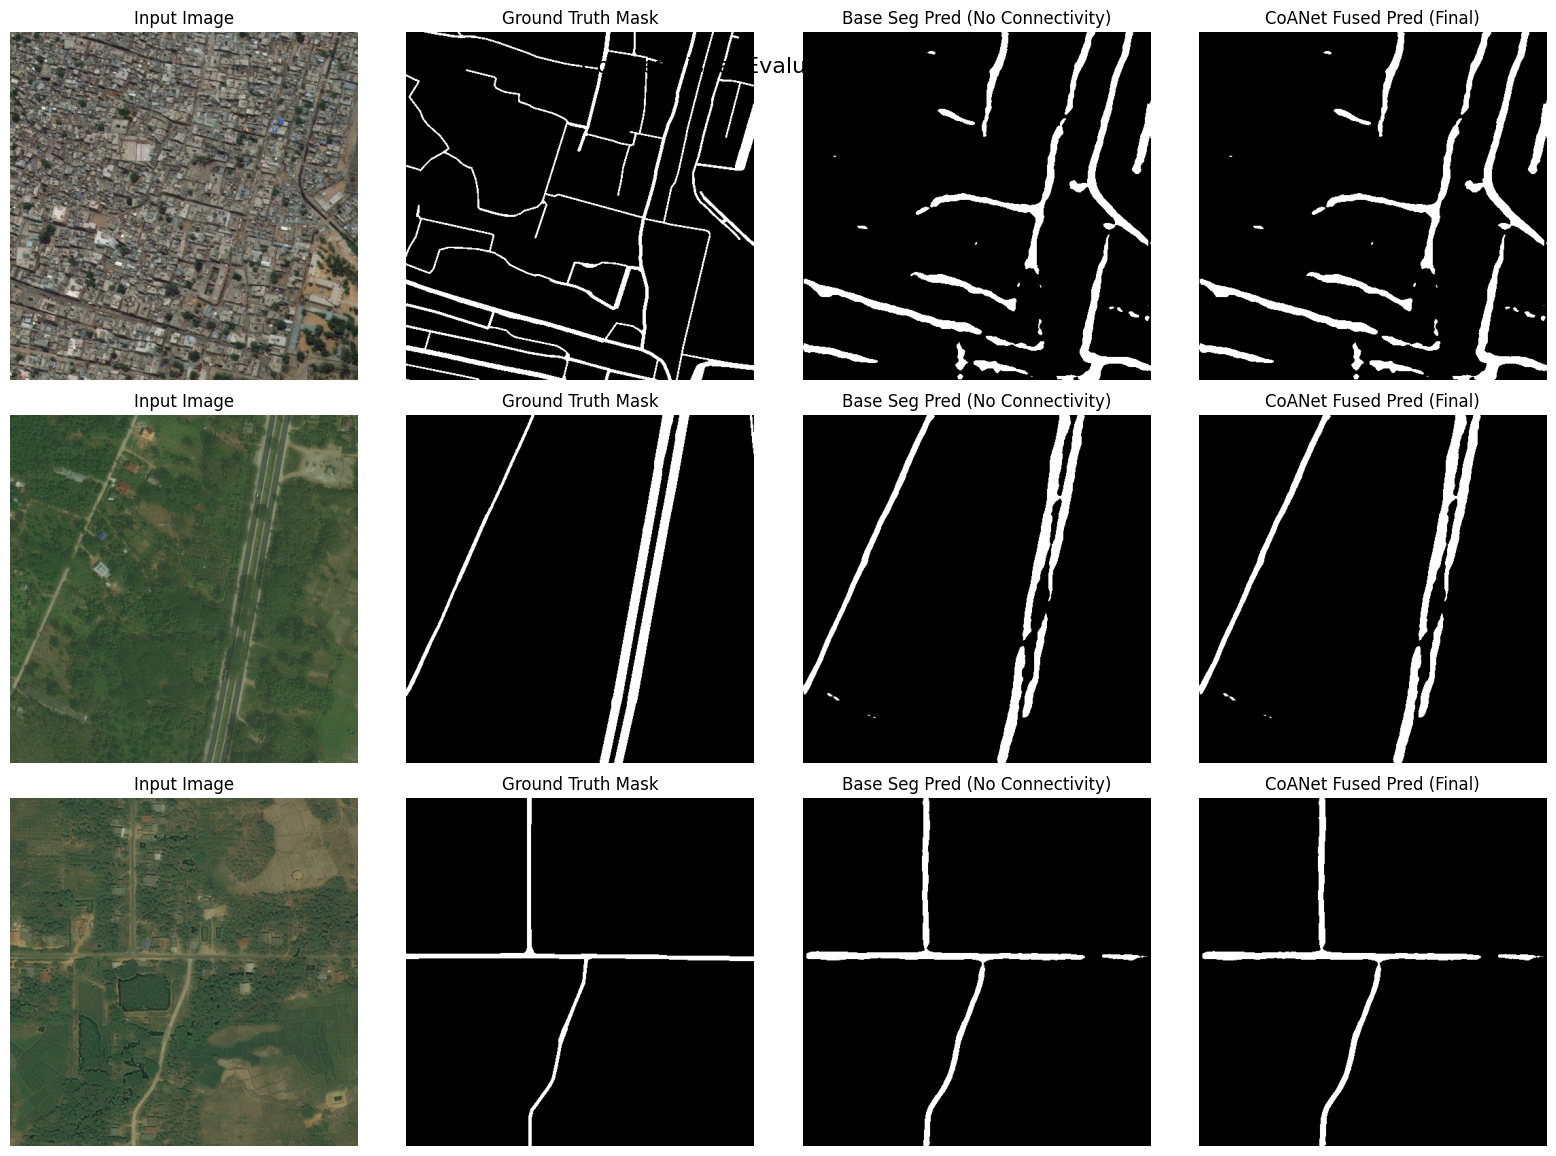

In [ ]:

import matplotlib.pyplot as plt
import random

def denormalize_image(tensor: torch.Tensor) -> np.ndarray:
    """Reverts the ImageNet normalization to display RGB images properly."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor.cpu() * std + mean
    tensor = torch.clamp(tensor, 0.0, 1.0)
    return tensor.permute(1, 2, 0).numpy()

def visualize_random_predictions(num_samples: int = 4):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    checkpoint_path = "/content/drive/MyDrive/CoANet_Checkpoints/best_coanet.pth"
    dataset_path = "/content/dataset/DeepGlobe"

    # 1. Load Model
    model = CoANet(pretrained_backbone=False).to(device)
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()

    # 2. Reconstruct Validation Dataset
    full_train_dataset = CoANetDataset(root_dir=dataset_path, phase='train', img_size=512, has_gt=True)
    val_dataset = copy.deepcopy(full_train_dataset)
    val_dataset.phase = 'valid'
    val_dataset.transform = val_dataset._get_transforms()

    val_size = int(len(full_train_dataset) * 0.10)
    generator = torch.Generator().manual_seed(42)
    _, val_indices = torch.utils.data.random_split(
        range(len(full_train_dataset)), [len(full_train_dataset) - val_size, val_size], generator=generator
    )
    val_data = torch.utils.data.Subset(val_dataset, val_indices.indices)

    # Use shuffle=True to get DIFFERENT random images every time this cell is executed!
    viz_loader = DataLoader(val_data, batch_size=num_samples, shuffle=True)

    # 3. Fetch one random batch
    batch = next(iter(viz_loader))
    images = batch['image'].to(device)
    targets = batch['seg_target'].to(device)

    with torch.no_grad():
        # Get raw segmentation and fused predictions
        outputs = model(images)
        raw_seg_prob = torch.sigmoid(outputs['seg_logits'])
        fused_prob = model.inference_fusion(images, threshold=0.5)

    # 4. Plotting
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))
    plt.suptitle(f"CoANet Visual Evaluation (Epoch {checkpoint.get('epoch', 'N/A')})", fontsize=16, y=0.92)

    for i in range(num_samples):
        # Original Image
        img_rgb = denormalize_image(images[i])
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis('off')

        # Ground Truth
        gt_mask = targets[i].cpu().squeeze().numpy()
        axes[i, 1].imshow(gt_mask, cmap='gray')
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis('off')

        # Raw Segmentation Prediction
        raw_mask = (raw_seg_prob[i].cpu().squeeze().numpy() > 0.5).astype(np.float32)
        axes[i, 2].imshow(raw_mask, cmap='gray')
        axes[i, 2].set_title("Base Seg Pred (No Connectivity)")
        axes[i, 2].axis('off')

        # Fused CoANet Prediction (Seg + Connectivity)
        fused_mask = (fused_prob[i].cpu().squeeze().numpy() > 0.5).astype(np.float32)
        axes[i, 3].imshow(fused_mask, cmap='gray')
        axes[i, 3].set_title("CoANet Fused Pred (Final)")
        axes[i, 3].axis('off')

    plt.tight_layout()
    plt.show()

# Run the dynamic visualizer
visualize_random_predictions(num_samples=3)